rumz
# Notebook for creating HDR images for HSI
### April 25
#### V. 1.0.0


This notebook processes hyperspectral images of ice.
To run:
- ensure datasetPath points to the correct directory file
- Insert Core and Section for whichever images to be run

In [1]:
# Importing Python Libraries
import warnings
import sys
import os

# Add the processing folder to the Python path
processing_path = os.path.abspath(os.path.join('..', 'processing'))
if processing_path not in sys.path:
    sys.path.append(processing_path)

#Importing Python Libraries and Packages
import pandas as pd
import numpy as np
import set_icespec_path as tool
import set_bubbles_path as tool2
icespec_code_path=tool.add_icespec_code_dir()
bubble_code_path=tool2.add_bubble_code_dir()
tool.add_icespec_code_dir()
tool2.add_bubble_code_dir()
from icespec import icespec_process2_module as processice
from bubbles import bubbles_process_module as processbubbles
from HDR import hdr_processing_module as processhdr
from icespec import savePNG
from icespec import ageConversion
from HDR import hdr_csv_capture_module as cap

In [2]:
datasetPath = '/data/icecores/HSI_2024.csv' #path to csv file on computer or server

outputDir = '/data/icecores/Output' #png output path

CoreID = "ALHIC 2302" #insert CoreID from excel file inside quotation marks
SectionID = "29 Sec 33" #insert Tube/Section from excel file inside quotation marks

Debug = True
SCRIPT_ID = "HDR_NB"

In [3]:
dataList = processhdr.getDataPath(CoreID, SectionID, datasetPath, outputDir, Debug)

outputPath = processhdr.make_dir(dataList, SCRIPT_ID)
print("Output Path: ", outputPath)

Reflectance Image:
  Path:          /data/icecores/July2024/ALHIC2302-29_0003_HSI_UM_Jul24
  Top Depth:     26.07 m
  Bottom Depth:  27.03 m
  Length:        0.96 m
  Save Path:     /data/icecores/Output/AN/ALHIC/ALHIC2302/ALHIC2302-29
  Dimensions:    [1340, 6820, 100, 900]
  Top Light:     100%
  Bottom Light:  0%
  Exposure:      16
  Data ID:      HSIUM-104

Low Exposure Image:
  Path:          /data/icecores/July2024/ALHIC2302-29_0001_HSI_UM_Jul24
  Top Depth:     26.07 m
  Bottom Depth:  27.03 m
  Length:        0.96 m
  Save Path:     /data/icecores/Output/AN/ALHIC/ALHIC2302/ALHIC2302-29
  Dimensions:    [1340, 6820, 100, 900]
  Top Light:     75%
  Bottom Light:  100%
  Exposure:      2
  Data ID:      HSIUM-102

High Exposure Image:
  Path:          /data/icecores/July2024/ALHIC2302-29_0002_HSI_UM_Jul24
  Top Depth:     26.07 m
  Bottom Depth:  27.03 m
  Length:        0.96 m
  Save Path:     /data/icecores/Output/AN/ALHIC/ALHIC2302/ALHIC2302-29
  Dimensions:    [1340, 6820, 1

Image height: 7334
img_startLn: 1340
img_endLn: 6820


/home/rumz/anaconda3/envs/HSenv/lib/python3.12/site-packages/spectral/graphics/spypylab.py:796: UserWarning: Failed to create RectangleSelector object. Interactive pixel class labeling will be unavailable.
  warnings.warn(msg)


Image height: 7335
img_startLn: 1340
img_endLn: 6820
Image height: 7335
img_startLn: 1340
img_endLn: 6820
Reflectance calculated. Dimensions: (5480, 700, 224)
(5480, 700, 224)
(5480, 700, 224)


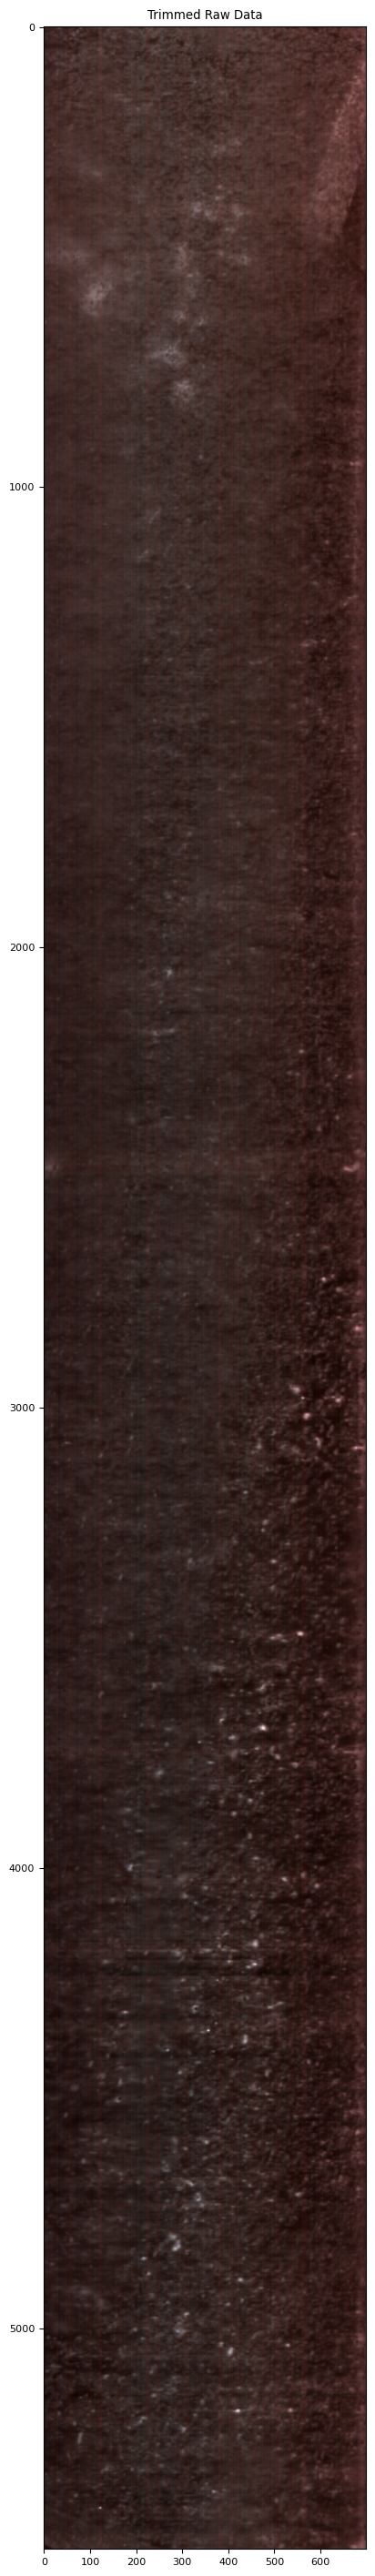

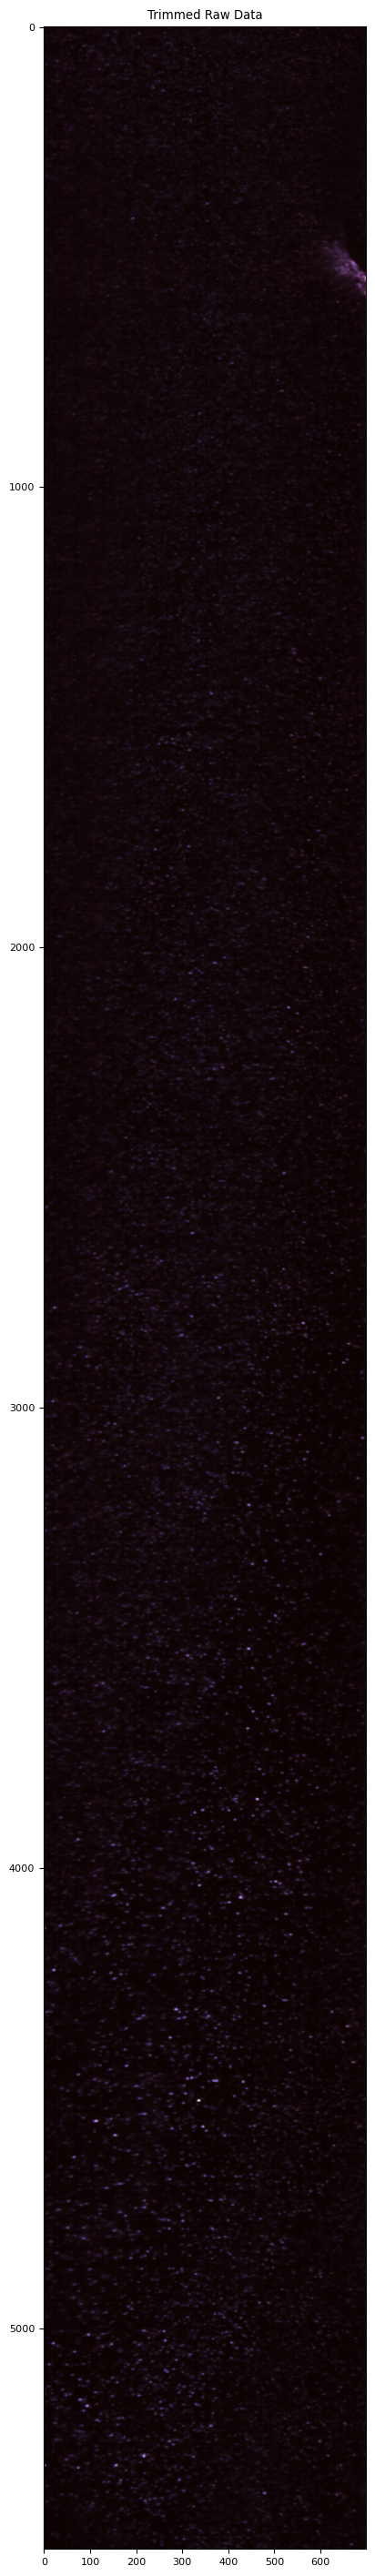

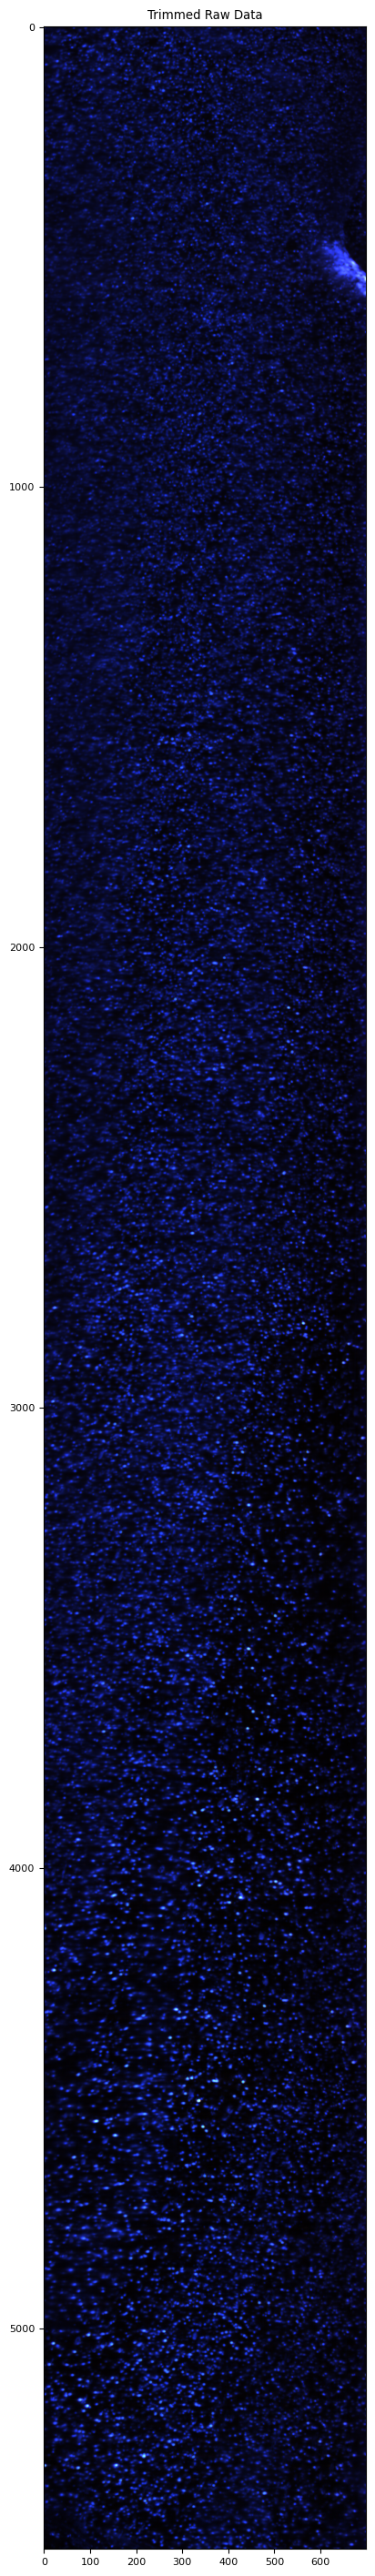

In [4]:
imgs = processhdr.getEnviData(dataList)
trimmedImgs = processhdr.trim(imgs, dataList)

correctedImgs = processhdr.reflectance(trimmedImgs, Debug)

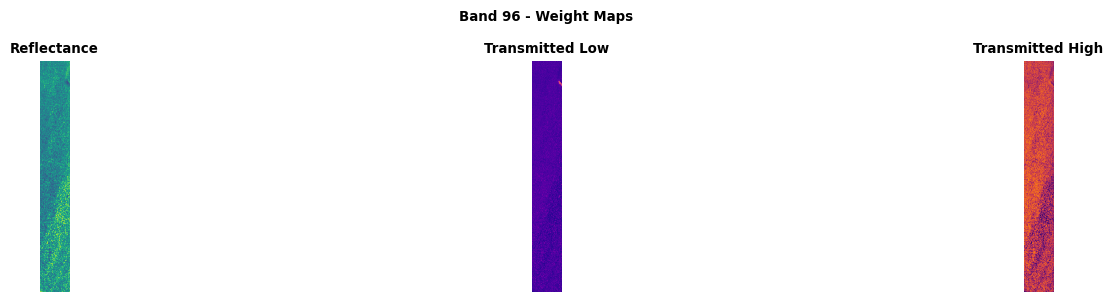

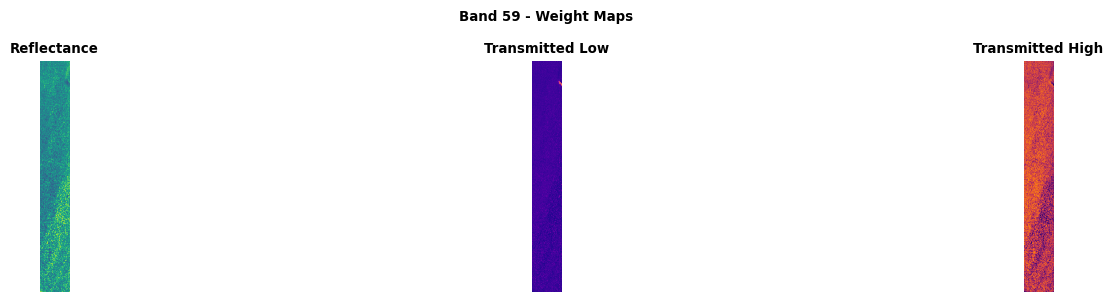

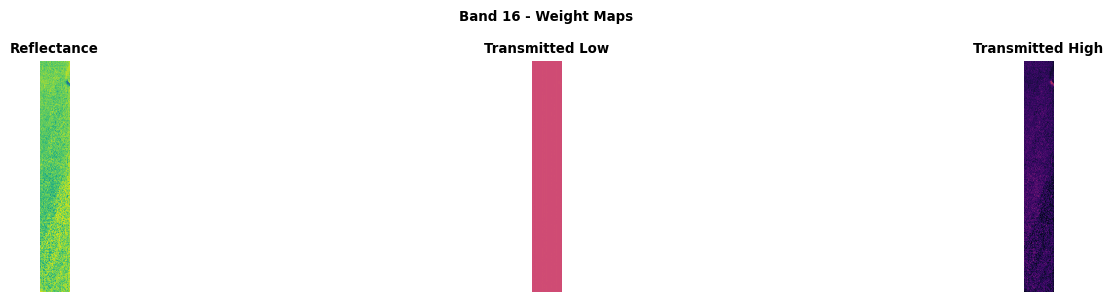

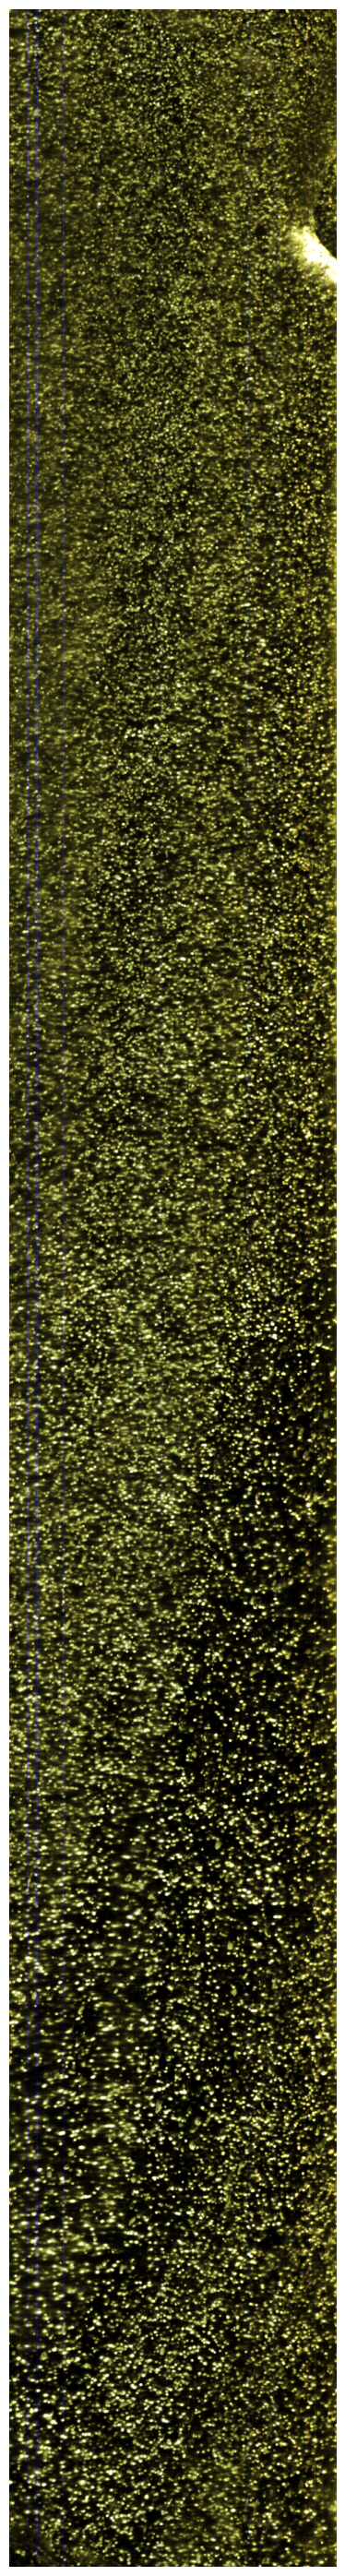

In [5]:
combined_img = processhdr.combine_imgs(correctedImgs, Debug, save=True, savepath=outputPath)

In [6]:
filtered_img, fwhm = processice.remove_bands(combined_img, trimmedImgs[1][1], imgs[2][3])
#previewed_img = processice.previewImg(filtered_img, "Filtered Image")
inpainted_img = processice.bubbles(filtered_img, imgs[2][3])
flattened_img = processice.flatten_data(inpainted_img)

rematrix_img = processice.resize_matrix(flattened_img, trimmedImgs[1], pc_num = 3) #pc_num can be changed

DSName = outputPath.parent.name
filename = f"{DSName}HDR"
eq_img = processice.equalize(rematrix_img, save=True, savePath=f"{outputPath}/{filename}")
readme_path = outputPath / "README.md"
with readme_path.open("a") as f:
    f.write(f"\n###  Output File: {filename}\n- {DSName}_equalized.png: HDR image equalized\n")

TypeError: remove_bands() missing 1 required positional argument: 'fwhm'